In [3]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [38]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Data_Analytics\Analysis\diabetes.csv")

# select only numerical columns
numeric_cols = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']
num_df = df.select_dtype('number')

AttributeError: 'DataFrame' object has no attribute 'select_dtype'

In [6]:
# Handle Missing Values
imputer = SimpleImputer(strategy = 'mean')
data_imputes = imputer.fit_transform(df[numeric_cols])
data_clean = pd.DataFrame(data_imputes,columns=numeric_cols)

In [7]:
# Standardize (important for pca)
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_clean)

In [8]:
# Apply PCA
pca = PCA(n_components=5)
data_pca = pca.fit_transform(data_scaled)

In [13]:
# Check how much information each component keep
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

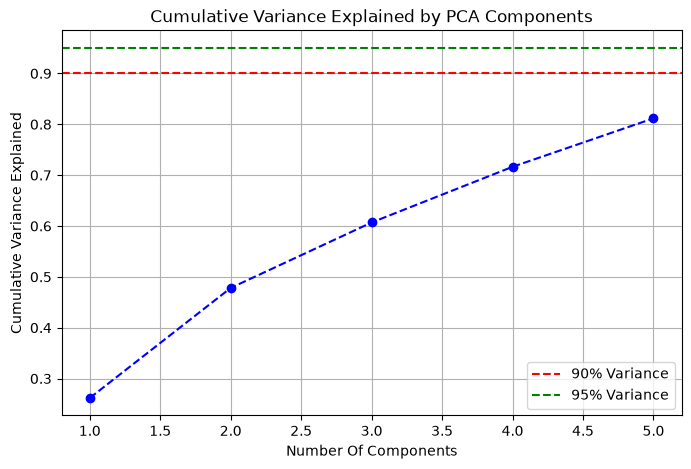

In [17]:
# Plot ciumulative variance 
plt.figure(figsize=(8,5))
plt.plot(range(1,len(cumulative_variance)+1),cumulative_variance,marker="o",linestyle='--',color='b')
plt.title('Cumulative Variance Explained by PCA Components')
plt.xlabel('Number Of Components')
plt.ylabel('Cumulative Variance Explained')
plt.axhline(y=0.9,color='r',linestyle='--',label='90% Variance')
plt.axhline(y=0.95,color='g',linestyle='--',label='95% Variance') 
plt.legend()
plt.grid(True)
plt.show()

In [18]:
# Print Variance Information 
print('Explained Varinace Ration:')
print(explained_variance.round(3))
print('\nCumulative Varinaace :')
print(cumulative_variance.round(3))

Explained Varinace Ration:
[0.262 0.216 0.129 0.109 0.095]

Cumulative Varinaace :
[0.262 0.478 0.607 0.716 0.812]


In [22]:
# Find Feature Contribution
loading = pd.DataFrame(pca.components_.T, # Transpose to get feature as rows
                       columns=[f'PC{i+1}' for i in range(pca.n_components_)],
                        index = numeric_cols)
print('Feature Loadings :',loading.round(3))

Feature Loadings :                             PC1    PC2    PC3    PC4    PC5
Pregnancies               0.128  0.594  0.013  0.081  0.476
Glucose                   0.393  0.174 -0.468 -0.404 -0.466
BloodPressure             0.360  0.184  0.535  0.056 -0.328
SkinThickness             0.440 -0.332  0.238  0.038  0.488
Insulin                   0.435 -0.251 -0.337 -0.350  0.347
BMI                       0.452 -0.101  0.362  0.054 -0.253
DiabetesPedigreeFunction  0.271 -0.122 -0.433  0.834 -0.120
Age                       0.198  0.621 -0.075  0.071  0.109


In [25]:
# Use Priciple components for logistic regression 
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

index_of_95 = np.argmax(cumulative_variance >= 0.95)
#np.argmax returns the index of the first 'True'. if no True found , it return 0. 
# We must check if the 95% target was actually reacged at that index

if cumulative_variance[index_of_95] >= 0.95:
    # if the target was reached , n_opt is the index + 1 (to correct for 0-indexing)
    n_opt = index_of_95+1
else:
    # if the target was not reached , use all available
    n_opt = len(explained_variance)
print(n_opt)

5


In [26]:
# Use the optimally reduced data for modeling
X_pca_reduced = data_pca[:,:n_opt]
y = df['Outcome']

X_train,X_test,y_train,y_test = train_test_split(X_pca_reduced,y,test_size=0.3,random_state=42,stratify=y)

In [33]:
model = LogisticRegression(max_iter = 1000)
model.fit(X_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [34]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test,y_pred)
print(f'Model Accuracy :- {accuracy:.4f}')

Model Accuracy :- 0.7403
